# TRUSTSR Lab 03.01 — Atomic Checkpoint and Audit Persistence

**Project:** TRUSTSR — Trust-Aware Causal Semantic Recovery for Long-Horizon Agentic Systems  
**Phase:** Lab 03 — Reliability and evidence integrity  
**Status:** Synthetic local prototype | Version 0.1.0

## Why this lab exists
Lab 02's final PDF identified a consistency gap: the checkpoint update commits to SQLite before the audit event is appended to an in-memory list. A process failure in between could leave a committed checkpoint without a matching audit event.

This lab tests a narrow remedy: **write the checkpoint version and its audit event in the same SQLite transaction**, then verify the persisted audit chain after reopening the database.

## Experiments
1. Accept a newer checkpoint and persist its audit event atomically.
2. Reject stale/replayed versions and persist those decisions.
3. Inject a failure before commit; verify neither the checkpoint update nor audit event commits.
4. Close and reopen the database; verify state and audit rows persist.
5. Verify audit-chain integrity and detect a modified payload.
6. Export scenario, audit, and validation CSVs.

**Evidence boundary:** All requests and checkpoint states are synthetic. This tests the local SQLite implementation under the scenarios below; it does not prove production power-loss behavior, distributed consistency, or resistance to privileged database tampering.

## 1. Imports and execution environment

In [1]:
import os, json, sqlite3, tempfile, hashlib, uuid, sys, platform
from datetime import datetime, timezone
import pandas as pd
import matplotlib.pyplot as plt

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("SQLite:", sqlite3.sqlite_version)
print("Execution UTC:", datetime.now(timezone.utc).isoformat())
print("Evidence classification: synthetic local simulation")

Python: 3.12.3
Platform: Linux-6.18.44-fc-v114-x86_64-with-glibc2.39
SQLite: 3.45.1
Execution UTC: 2026-10-11T10:26:34.005972+00:00
Evidence classification: synthetic local simulation


## 2. Create the SQLite database

In [2]:
db_fd, DB_PATH = tempfile.mkstemp(prefix="trustsr_lab03_01_", suffix=".sqlite")
os.close(db_fd)

def open_db():
    connection = sqlite3.connect(DB_PATH, timeout=10, isolation_level=None)
    connection.execute("PRAGMA journal_mode=WAL")
    connection.execute("PRAGMA synchronous=FULL")
    connection.execute("CREATE TABLE IF NOT EXISTS checkpoint_state (singleton_id INTEGER PRIMARY KEY CHECK(singleton_id=1), high_water_mark INTEGER NOT NULL CHECK(high_water_mark>=0))")
    connection.execute("INSERT OR IGNORE INTO checkpoint_state(singleton_id, high_water_mark) VALUES (1, 0)")
    connection.execute("CREATE TABLE IF NOT EXISTS audit_events (sequence INTEGER PRIMARY KEY AUTOINCREMENT, transaction_id TEXT NOT NULL UNIQUE, timestamp_utc TEXT NOT NULL, checkpoint_version INTEGER, outcome TEXT NOT NULL, reason TEXT NOT NULL, mark_before INTEGER NOT NULL, mark_after INTEGER NOT NULL, previous_hash TEXT NOT NULL, event_hash TEXT NOT NULL)")
    return connection

conn = open_db()
print("Initial high-water mark:", conn.execute("SELECT high_water_mark FROM checkpoint_state").fetchone()[0])
print("Initial audit rows:", conn.execute("SELECT COUNT(*) FROM audit_events").fetchone()[0])

Initial high-water mark: 0
Initial audit rows: 0


## 3. Canonical hashing and persisted audit-chain verification

In [3]:
GENESIS_HASH = "0" * 64

def canonical_bytes(obj):
    return json.dumps(obj, sort_keys=True, separators=(",", ":"), ensure_ascii=False).encode("utf-8")

def hash_event(event_without_hash):
    return hashlib.sha256(canonical_bytes(event_without_hash)).hexdigest()

AUDIT_FIELDS = ["sequence", "transaction_id", "timestamp_utc", "checkpoint_version", "outcome", "reason", "mark_before", "mark_after", "previous_hash"]

def fetch_audit_rows(connection=None):
    connection = connection or conn
    rows = connection.execute("SELECT sequence, transaction_id, timestamp_utc, checkpoint_version, outcome, reason, mark_before, mark_after, previous_hash, event_hash FROM audit_events ORDER BY sequence").fetchall()
    return [dict(zip(AUDIT_FIELDS + ["event_hash"], row)) for row in rows]

def verify_persisted_chain(log):
    issues = []
    expected_previous = GENESIS_HASH
    for expected_sequence, stored in enumerate(log, start=1):
        event = {key: stored[key] for key in AUDIT_FIELDS}
        if event["sequence"] != expected_sequence:
            issues.append({"sequence": expected_sequence, "issue": "sequence_gap_or_reordering"})
        if event["previous_hash"] != expected_previous:
            issues.append({"sequence": expected_sequence, "issue": "previous_hash_mismatch"})
        if stored["event_hash"] != hash_event(event):
            issues.append({"sequence": expected_sequence, "issue": "event_hash_mismatch"})
        expected_previous = stored["event_hash"]
    return {"valid": not issues, "issues": issues, "events_checked": len(log)}

print("Hash-chain verifier ready.")

Hash-chain verifier ready.


## 4. Atomic submit operation

In [4]:
def submit_version(version, *, inject_precommit_failure=False):
    txid = str(uuid.uuid4())
    timestamp = datetime.now(timezone.utc).isoformat()
    conn.execute("BEGIN IMMEDIATE")
    try:
        before = int(conn.execute("SELECT high_water_mark FROM checkpoint_state WHERE singleton_id=1").fetchone()[0])
        valid_version = isinstance(version, int) and not isinstance(version, bool) and version >= 1
        accepted = valid_version and version > before
        if not valid_version:
            outcome, reason, after = "rejected", "invalid_version", before
        elif accepted:
            outcome, reason, after = "accepted", "committed", version
            conn.execute("UPDATE checkpoint_state SET high_water_mark=? WHERE singleton_id=1", (version,))
        else:
            outcome, reason, after = "rejected", "stale_or_replay", before

        if inject_precommit_failure:
            raise RuntimeError("injected_precommit_failure")

        previous_row = conn.execute("SELECT event_hash FROM audit_events ORDER BY sequence DESC LIMIT 1").fetchone()
        previous_hash = previous_row[0] if previous_row else GENESIS_HASH
        sequence = int(conn.execute("SELECT COALESCE(MAX(sequence), 0) + 1 FROM audit_events").fetchone()[0])
        event = {
            "sequence": sequence, "transaction_id": txid, "timestamp_utc": timestamp,
            "checkpoint_version": version if valid_version else None, "outcome": outcome,
            "reason": reason, "mark_before": before, "mark_after": after, "previous_hash": previous_hash
        }
        event_hash = hash_event(event)
        conn.execute("INSERT INTO audit_events (sequence, transaction_id, timestamp_utc, checkpoint_version, outcome, reason, mark_before, mark_after, previous_hash, event_hash) VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?)",
                     (sequence, txid, timestamp, event["checkpoint_version"], outcome, reason, before, after, previous_hash, event_hash))
        conn.execute("COMMIT")
        return {"transaction_id": txid, "accepted": bool(accepted), "reason": reason, "mark_before": before, "mark_after": after}
    except Exception as exc:
        conn.execute("ROLLBACK")
        mark = int(conn.execute("SELECT high_water_mark FROM checkpoint_state WHERE singleton_id=1").fetchone()[0])
        return {"transaction_id": txid, "accepted": False, "reason": str(exc), "mark_before": before if "before" in locals() else mark, "mark_after": mark}

print("Atomic submit operation defined.")

Atomic submit operation defined.


## 5. Acceptance, replay, and injected-failure tests

In [5]:
scenario_rows = []

def run_case(name, version, expected_accepted, expected_mark, inject=False, expected_audit_delta=1):
    before_audit = int(conn.execute("SELECT COUNT(*) FROM audit_events").fetchone()[0])
    result = submit_version(version, inject_precommit_failure=inject)
    after_audit = int(conn.execute("SELECT COUNT(*) FROM audit_events").fetchone()[0])
    row = {
        "scenario": name, "version": version, "accepted": result["accepted"], "reason": result["reason"],
        "mark_before": result["mark_before"], "mark_after": result["mark_after"],
        "audit_rows_before": before_audit, "audit_rows_after": after_audit,
        "audit_row_delta": after_audit-before_audit, "expected_accepted": expected_accepted,
        "expected_mark_after": expected_mark, "expected_audit_delta": expected_audit_delta,
        "assertion_passed": (result["accepted"] == expected_accepted and result["mark_after"] == expected_mark and after_audit-before_audit == expected_audit_delta)
    }
    scenario_rows.append(row)
    assert row["assertion_passed"], row
    return result

run_case("accept_v2", 2, True, 2)
run_case("reject_stale_v1", 1, False, 2)
run_case("reject_replay_v2", 2, False, 2)
run_case("precommit_failure_v4", 4, False, 2, inject=True, expected_audit_delta=0)
run_case("accept_v3_after_failure", 3, True, 3)

scenario_df = pd.DataFrame(scenario_rows)
display(scenario_df)
print("Current high-water mark:", conn.execute("SELECT high_water_mark FROM checkpoint_state").fetchone()[0])
print("Persisted audit rows:", conn.execute("SELECT COUNT(*) FROM audit_events").fetchone()[0])

                  scenario  version  accepted                      reason  mark_before  mark_after  audit_rows_before  audit_rows_after  audit_row_delta  expected_accepted  expected_mark_after  \
0                accept_v2        2      True                   committed            0           2                  0                 1                1               True                    2   
1          reject_stale_v1        1     False             stale_or_replay            2           2                  1                 2                1              False                    2   
2         reject_replay_v2        2     False             stale_or_replay            2           2                  2                 3                1              False                    2   
3     precommit_failure_v4        4     False  injected_precommit_failure            2           2                  3                 3                0              False                    2   
4  accept_v3_after_f

Current high-water mark: 3
Persisted audit rows: 4


## 6. Verify audit consistency and restart persistence

In [6]:
audit_log = fetch_audit_rows()
chain_result = verify_persisted_chain(audit_log)
print("Persisted audit chain:", chain_result)
assert chain_result["valid"]

for row in scenario_rows:
    if row["scenario"] == "precommit_failure_v4":
        assert row["audit_row_delta"] == 0
    else:
        assert row["audit_row_delta"] == 1

mark_before_restart = int(conn.execute("SELECT high_water_mark FROM checkpoint_state WHERE singleton_id=1").fetchone()[0])
rows_before_restart = int(conn.execute("SELECT COUNT(*) FROM audit_events").fetchone()[0])
conn.close()
conn = open_db()
mark_after_restart = int(conn.execute("SELECT high_water_mark FROM checkpoint_state WHERE singleton_id=1").fetchone()[0])
rows_after_restart = int(conn.execute("SELECT COUNT(*) FROM audit_events").fetchone()[0])
restart_result = {
    "mark_before_restart": mark_before_restart, "mark_after_restart": mark_after_restart,
    "audit_rows_before_restart": rows_before_restart, "audit_rows_after_restart": rows_after_restart,
    "state_persisted": mark_before_restart == mark_after_restart,
    "audit_rows_persisted": rows_before_restart == rows_after_restart
}
display(pd.DataFrame([restart_result]))
assert restart_result["state_persisted"] and restart_result["audit_rows_persisted"]
assert verify_persisted_chain(fetch_audit_rows())["valid"]

Persisted audit chain: {'valid': True, 'issues': [], 'events_checked': 4}


   mark_before_restart  mark_after_restart  audit_rows_before_restart  audit_rows_after_restart  state_persisted  audit_rows_persisted
0                    3                   3                          4                         4             True                  True

## 7. Tamper-detection test

In [7]:
persisted_log = fetch_audit_rows()
tampered_log = [dict(event) for event in persisted_log]
tampered_log[0]["reason"] = "modified_after_commit"
tamper_result = verify_persisted_chain(tampered_log)
print("Tampered chain:", tamper_result)
assert not tamper_result["valid"]

validation_df = pd.DataFrame([
    {"test": "intact_persisted_chain", "valid": verify_persisted_chain(persisted_log)["valid"]},
    {"test": "tampered_payload", "valid": verify_persisted_chain(tampered_log)["valid"]},
    {"test": "restart_state_persisted", "valid": restart_result["state_persisted"]},
    {"test": "restart_audit_persisted", "valid": restart_result["audit_rows_persisted"]},
])
display(validation_df)

Tampered chain: {'valid': False, 'issues': [{'sequence': 1, 'issue': 'event_hash_mismatch'}], 'events_checked': 4}


                      test  valid
0   intact_persisted_chain   True
1         tampered_payload  False
2  restart_state_persisted   True
3  restart_audit_persisted   True

## 8. Plot and export CSVs

CSV exports created:
- trustsr_lab03_01_atomic_scenarios.csv
- trustsr_lab03_01_persisted_audit_log.csv
- trustsr_lab03_01_validation_results.csv
- trustsr_lab03_01_restart_persistence.csv


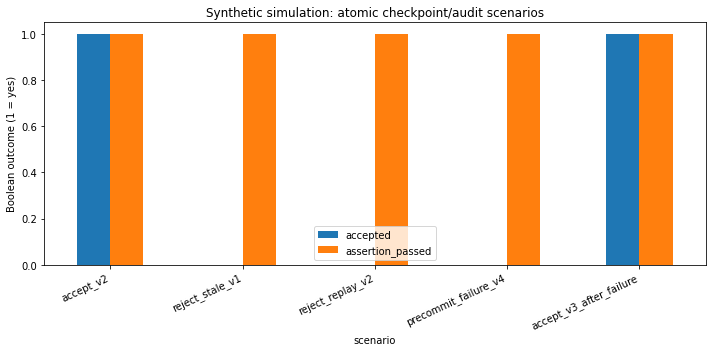

In [8]:
plot_data = scenario_df.set_index("scenario")[["accepted", "assertion_passed"]].astype(int)
ax = plot_data.plot(kind="bar", figsize=(10, 5))
ax.set_title("Synthetic simulation: atomic checkpoint/audit scenarios")
ax.set_ylabel("Boolean outcome (1 = yes)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

scenario_df.to_csv("trustsr_lab03_01_atomic_scenarios.csv", index=False)
pd.DataFrame(audit_log).to_csv("trustsr_lab03_01_persisted_audit_log.csv", index=False)
validation_df.to_csv("trustsr_lab03_01_validation_results.csv", index=False)
pd.DataFrame([restart_result]).to_csv("trustsr_lab03_01_restart_persistence.csv", index=False)
print("CSV exports created:")
print("- trustsr_lab03_01_atomic_scenarios.csv")
print("- trustsr_lab03_01_persisted_audit_log.csv")
print("- trustsr_lab03_01_validation_results.csv")
print("- trustsr_lab03_01_restart_persistence.csv")

## 9. Final assertions

In [9]:
assert scenario_df["assertion_passed"].all()
assert conn.execute("SELECT high_water_mark FROM checkpoint_state WHERE singleton_id=1").fetchone()[0] == 3
assert verify_persisted_chain(fetch_audit_rows())["valid"]
assert not verify_persisted_chain(tampered_log)["valid"]
assert restart_result["state_persisted"] and restart_result["audit_rows_persisted"]
assert len(fetch_audit_rows()) == 4
print("PASS: checkpoint state and audit event commit together.")
print("PASS: injected pre-commit failure leaves neither state update nor audit row.")
print("PASS: stale and replayed versions are rejected and audited.")
print("PASS: persisted audit chain validates after database reopen.")
print("PASS: payload tampering is detected.")
print("All TRUSTSR Lab 03.01 assertions passed.")

PASS: checkpoint state and audit event commit together.
PASS: injected pre-commit failure leaves neither state update nor audit row.
PASS: stale and replayed versions are rejected and audited.
PASS: persisted audit chain validates after database reopen.
PASS: payload tampering is detected.
All TRUSTSR Lab 03.01 assertions passed.


## 10. Interpretation and limitations

### What this lab tests
The checkpoint high-water mark and audit row are written in the same SQLite transaction. Under the tested injected pre-commit failure, both are rolled back. Accepted and rejected decisions are persisted, and the hash chain verifies after closing and reopening the database.

### Important limits
- This is a synthetic local SQLite experiment, not production evidence.
- The injected failure is an application-level exception before commit, not a real power cut or forced process termination.
- SQLite behavior depends on runtime, filesystem, and deployment configuration.
- A privileged attacker who can alter the database can rewrite rows and hashes unless the trusted head is independently protected.
- This lab does not test multiple processes, distributed consensus, external side effects, or real autonomous agents.

### Defensible research wording
“In the tested synthetic local scenarios, checkpoint state and audit events were persisted in one SQLite transaction; the injected pre-commit exception left neither change committed.”
Do not generalize this to production crash safety or universal tamper resistance.